[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harvard-CS1090/2026-CS1090A-public/blob/sec07-2026/sec07/cs1090a_sec07_student.ipynb)

> **On Colab, do `File → Save a copy in Drive` before you start.** This notebook opens from GitHub, so you can type in it and run it right away — but nothing is being saved anywhere. Close the tab and the work is gone. Saving a copy first gives you one that persists in your own Drive.

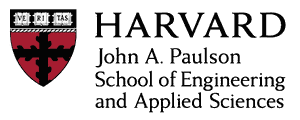

# CS1090A Introduction to Data Science

### Section 7 — Logistic Regression

**Logistic regression** is a classification model. Here we use **binary logistic regression**
for two classes, coded 0 and 1. Instead of predicting a continuous outcome, it predicts the
probability of belonging to class 1; the probability of class 0 is $1-p$. A threshold turns
these probabilities into class predictions.

As we discussed, a supervised learning problem has **data, a model, a loss, and an
optimization procedure**:

- **Data:** predictors $\mathbf{x}_i$ and labels $y_i \in \{0,1\}$. We introduce our dataset below.
- **Model:** $p_i = P(Y_i=1\mid\mathbf{x}_i) = \dfrac{1}{1+e^{-(\beta_0+\boldsymbol{\beta}^{\mathsf T}\mathbf{x}_i)}}$.
- **Loss:** binary cross-entropy, the average negative log-likelihood: $L(\beta_0,\boldsymbol{\beta}) = -\dfrac{1}{n}\sum_{i=1}^{n}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]$.
- **Optimization:** choose the coefficients $\beta_0$ and $\boldsymbol{\beta}$ to minimize this loss numerically on the development data.


<div style="background:#E8F1FF; border-left:6px solid #2563EB; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🎯 Objectives — what you should be able to do by the end</div>
<div>
<ul>
<li>Explain why a least-squares line can produce invalid probabilities for a binary outcome.</li>
<li>Fit a binary logistic regression model.</li>
<li>Interpret a coefficient as a change in log-odds or, after exponentiating, as an odds ratio.</li>
<li>Derive the decision boundary of a two-predictor logistic model.</li>
<li>Use polynomial terms to produce a curved decision boundary.</li>
<li>Choose the strength of an L1 penalty by cross-validation.</li>
<li>Measure a model's reliance on predictors using permutation importance, and explain why correlated predictors should be shuffled together.</li>
<li>Read a confusion matrix.</li>
<li>Choose a classification threshold using out-of-fold development predictions.</li>
<li>Evaluate the chosen model and threshold on a held-out test set.</li>
</ul>
</div>
</div>

**Coloured boxes:** 🤔 commit to a prediction before running the code · 🏋️ write code (look for `# your code here`) · 💬 stop running cells and discuss · ⭐ the point of the exercise · 🧠 what to carry out of the room · 🔍 an appendix item to work through on your own afterwards.

**The data.** 569 breast tumours, each described by ten measurements of the cell nuclei in
a digitized image, and a diagnosis: malignant or benign (Street, Wolberg and Mangasarian,
1993). The data ships with scikit-learn.

Every model so far in the course has predicted a number. This section predicts a yes/no
outcome, coded 0/1: we build logistic regression from one predictor, then two, then all ten, and
then turn its predicted probabilities into decisions.

## Setup

Load the data, hold out a test set, and set the baseline every classifier must beat.

### Load the data

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression, LogisticRegressionCV
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
# Silence scikit-learn's deprecation notices about the `penalty` argument
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")

In [ ]:
# The file codes benign as 1. Flip it so that 1 = malignant, the positive class throughout.
bunch = load_breast_cancer(as_frame=True)
y_all = (bunch.target == 0).astype(int).rename("malignant")

# The ten "mean" columns are the predictors: each averaged over the nuclei in the image
predictors = [col for col in bunch.data.columns if col.startswith("mean ")]
X_all = bunch.data[predictors]
X_all.head(3).round(3)

In [ ]:
print(f"malignant: {y_all.sum()} of {len(y_all)} tumours ({y_all.mean():.1%})")

| Column | What it measures |
|---|---|
| `mean radius`, `mean perimeter`, `mean area` | the size of a nucleus (mm, mm, mm²) |
| `mean texture` | how much the grey level varies across a nucleus |
| `mean smoothness`, `mean compactness` | how much the radius varies around the outline; perimeter² / area − 1 |
| `mean concavity`, `mean concave points` | how deep the dents in the outline are, and how many there are |
| `mean symmetry`, `mean fractal dimension` | two more shape descriptors |
| `malignant` | **the outcome:** 1 if malignant, 0 if benign |

Three of the columns measure the same thing, size. Part 4 comes back to that.

### Development/test split

We hold out 25% of the rows as a test set. The split and the cross-validation folds are
**stratified**: each keeps the same share of malignant tumours as the whole, so no fold
holds noticeably more or fewer positives by chance.
The **development set** is used to fit the models and choose their settings. In each
cross-validation split, four folds are used to fit the model and the fifth is its
validation fold. The test set stays aside for the final check.


In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X_all, y_all, test_size=0.25, random_state=109, stratify=y_all
)
# Five stratified folds, reused for every cross-validation below
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print(f"development rows {len(X_dev)}   test rows {len(X_test)}")

### The baseline

**Accuracy** is the share of rows whose predicted class is correct. 

The **baseline**
predicts the more common class, benign, for every row. Every classifier below has to beat it.

In [ ]:
# Accuracy of predicting "benign" for every tumour
baseline_accuracy = 1 - y_dev.mean()
print(f"baseline accuracy: {baseline_accuracy:.3f}")

We begin with just one predictor, **mean radius**. Before fitting a model, let's look
at how this measurement is distributed for benign and malignant tumours in the
development set.


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, name, color in [(0, "benign", "#2563EB"), (1, "malignant", "#DC2626")]:
    ax.hist(X_dev.loc[y_dev == label, "mean radius"], bins=30, alpha=0.6, color=color,
            label=f"{name} ({(y_dev == label).sum()} tumours)")
ax.set(xlabel="mean radius (mm)", ylabel="number of tumours",
       title="mean radius by diagnosis, development rows")
ax.legend()
plt.show()

## Part 1. From a straight line to logistic regression

We already know linear regression, so we try it first to predict the 0/1 diagnosis from
mean radius. We check whether its predictions make sense as probabilities. Then we fit
logistic regression, which keeps its predicted probabilities between 0 and 1.


### Least squares on the 0/1 outcome

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict — the largest tumour</div>
<div>
We fit a least-squares line to the diagnosis (1 = malignant, 0 = benign) using mean radius.
For the largest tumour in the development rows, will the fitted value be close to 1, exactly 1,
or above 1? Commit before running the next cell.
</div>
</div>

In [ ]:
# Ordinary least squares on the 0/1 outcome, with mean radius as the only predictor
line = LinearRegression().fit(X_dev[["mean radius"]], y_dev)
fitted = line.predict(X_dev[["mean radius"]])

outside = ((fitted < 0) | (fitted > 1)).sum()
print(f"fitted values run from {fitted.min():.2f} to {fitted.max():.2f}; "
      f"{outside} of {len(fitted)} development tumours get a fitted value outside [0, 1]")

For each fitted model, we report two accuracies. **In-sample accuracy** evaluates the
model on the same development rows used to fit it. **Cross-validated accuracy** fits
a fresh model on four folds and evaluates it on the remaining validation fold,
repeating this for all five folds and averaging their accuracies.

`cross_val_score` performs these fitting and evaluation rounds internally. Each
round starts with an unfitted copy of the model. We use the same folds for linear
and logistic regression, and the test set is still held aside.


In [ ]:
# Classification accuracy: a fitted value above 0.5 predicts the malignant class.
# LinearRegression defaults to R-squared, so supply an accuracy scorer for CV.
def ols_classification_accuracy(model, X, y):
    predicted_class = (model.predict(X) > 0.5).astype(int)
    return accuracy_score(y, predicted_class)

line_cv_scores = cross_val_score(
    line, X_dev[["mean radius"]], y_dev,
    cv=skf, scoring=ols_classification_accuracy, error_score="raise",
)

pd.Series({
    "development (in-sample)": accuracy_score(y_dev, (fitted > 0.5).astype(int)),
    "cross-validated": line_cv_scores.mean(),
    "baseline": baseline_accuracy,
}).round(3)


In [ ]:
radius_grid = pd.DataFrame({"mean radius": np.linspace(6, 29, 200)})
jitter = np.random.default_rng(0).normal(0, 0.02, len(y_dev))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(X_dev["mean radius"], y_dev + jitter, s=12, alpha=0.5, color="#4B5563",
           label="tumours (0 = benign, 1 = malignant)")
ax.plot(radius_grid["mean radius"], line.predict(radius_grid), color="#DC2626", linewidth=2, label="least-squares line")
ax.axhline(0, color="grey", linewidth=1)
ax.axhline(1, color="grey", linewidth=1)
ax.set(yticks=[0, 1], xlabel="mean radius (mm)", ylabel="malignant (0/1) and fitted value",
       title="a straight line fitted to a 0/1 outcome")
ax.legend(loc="upper left")
plt.show()

<div style="background:#F3E8FF; border-left:6px solid #7E22CE; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">⭐ Insight — why a straight line is the wrong model</div>
<div>
Thresholding the line at 0.5 classifies many tumours correctly, and its cross-validated
accuracy can look good. But fitted values below 0 and above 1 cannot be probabilities.
Good classification accuracy does not make those values valid probability estimates.

A straight line also changes by the same amount for every extra millimetre. We want a
model whose probabilities stay between 0 and 1, with small changes near the extremes
and larger changes in the middle.
</div>
</div>

### From a linear score to a probability

Start with a **linear score** based on mean radius:

$$z = \beta_0 + \beta_1 \cdot \text{radius}.$$

This score is unbounded: it can be any real number. To turn it into a probability, we
pass it through the **logistic function**, also called the **sigmoid**:

$$\sigma(z) = \frac{1}{1+e^{-z}}.$$

For any finite score, the sigmoid gives a value between 0 and 1. A score of zero gives
0.5; large negative scores give probabilities near 0, and large positive scores give
probabilities near 1.

Our **logistic regression model** is therefore

$$P(\text{malignant}\mid\text{radius})
= \sigma(\beta_0 + \beta_1 \cdot \text{radius})
= \frac{1}{1+e^{-(\beta_0+\beta_1\cdot\text{radius})}}.$$

`LogisticRegression` fits the coefficients of this model by minimizing the binary
cross-entropy loss introduced above.


Let's look at the shape of the logistic function for three different slopes. Each curve
reaches a probability of 0.5 at a radius of 15. These curves illustrate the model before
we fit it to our data.


In [ ]:
# The sigmoid for three slopes, each with p = 0.5 at a radius of 15 mm
grid = np.linspace(5, 25, 300)
fig, ax = plt.subplots(figsize=(8, 4))
for slope, color in [(0.3, "#D97706"), (1.0, "#DC2626"), (3.0, "#7E22CE")]:
    ax.plot(grid, 1 / (1 + np.exp(-slope * (grid - 15))), color=color, linewidth=2,
            label=f"slope {slope} per mm")
ax.axhline(0.5, color="grey", linestyle=":", linewidth=1)
ax.axvline(15, color="grey", linestyle=":", linewidth=1)
ax.set(xlabel="mean radius (mm)", ylabel="P(malignant)",
       title="the slope sets how fast the probability changes near 50%")
ax.legend()
plt.show()

### Logistic regression on mean radius

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 1: fit logistic regression and read its coefficients (5 min)</div>
<div>
Fit <code style="background:rgba(0,0,0,0.06); color:#1F2937;">LogisticRegression(penalty=None)</code> on <code style="background:rgba(0,0,0,0.06); color:#1F2937;">mean radius</code>; <code style="background:rgba(0,0,0,0.06); color:#1F2937;">penalty=None</code> turns
off scikit-learn's default ridge penalty. Then, from the intercept <code style="background:rgba(0,0,0,0.06); color:#1F2937;">b0</code> and slope <code style="background:rgba(0,0,0,0.06); color:#1F2937;">b1</code> alone:
<ol>
<li>write <code style="background:rgba(0,0,0,0.06); color:#1F2937;">p_malignant(radius)</code> using the sigmoid formula above rather than <code style="background:rgba(0,0,0,0.06); color:#1F2937;">predict_proba</code> (the cell evaluates it at 10, 15 and 20 mm);</li>
<li>find the radius at which the model says 50% by solving <em>b0 + b1 · radius = 0</em>.</li>
</ol>
</div>
</div>

In [ ]:
logit_radius = LogisticRegression(penalty=None)

# your code here
logit_radius.fit(...)                                   # mean radius only, development rows
b0, b1 = logit_radius.intercept_[0], logit_radius.coef_[0, 0]

def p_malignant(radius):
    # The model's probability, from the two coefficients by the formula
    return ...

probabilities = {r: p_malignant(r) for r in (10, 15, 20)}
radius_at_50 = ...                                      # solve b0 + b1 * radius = 0


In [ ]:
print(f"intercept b0 = {b0:.3f}   slope b1 = {b1:.3f} per mm")
for r, p in probabilities.items():
    print(f"  P(malignant | radius = {r} mm) = {p:.3f}")
print(f"the model says 50% at a radius of {radius_at_50:.2f} mm")

In [ ]:
# Development and cross-validated accuracy, against the baseline
pd.Series({
    "development (in-sample)": accuracy_score(y_dev, logit_radius.predict(X_dev[["mean radius"]])),
    "cross-validated": cross_val_score(logit_radius, X_dev[["mean radius"]], y_dev, cv=skf).mean(),
    "baseline": baseline_accuracy,
}).round(3)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(X_dev["mean radius"], y_dev + jitter, s=12, alpha=0.5, color="#4B5563", label="tumours")
ax.plot(radius_grid["mean radius"], logit_radius.predict_proba(radius_grid)[:, 1], color="#DC2626", linewidth=2,
        label="logistic regression: P(malignant)")
ax.plot(radius_grid["mean radius"], line.predict(radius_grid), color="#D97706", linewidth=1.5, linestyle="--",
        label="least-squares line")
ax.axvline(radius_at_50, color="grey", linestyle=":", label=f"50% at {radius_at_50:.1f} mm")
ax.set(ylim=(-0.1, 1.1), xlabel="mean radius (mm)", ylabel="P(malignant)",
       title="logistic regression: the sigmoid gives probabilities")
ax.legend(loc="upper left", fontsize=9)
plt.show()

### Interpreting the fitted coefficients

Now that we have fitted the model, what do its coefficients mean? For a probability $p$,
the **odds** of the malignant class are $p/(1-p)$. The **log-odds** are the natural
logarithm of the odds:

$$\text{log-odds} = \log\frac{p}{1-p}.$$

Our logistic model passes the linear score $z$ through the sigmoid. Since
$p = 1/(1+e^{-z})$, its odds are $e^z$. Taking the logarithm gives

$$\log\frac{p}{1-p} = z = \beta_0 + \beta_1\cdot\text{radius}.$$

The **log-odds are linear in radius**, even though the probability follows a curved
sigmoid. Increasing radius by one unit adds $\beta_1$ to the log-odds, so it multiplies
the odds by $e^{\beta_1}$. This multiplier is the **odds ratio**. The change in probability
depends on the starting radius; it is not a constant amount.


<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 1: reading the slope</div>
<div>
<ol>
<li>When the radius grows by 1 mm, what happens to the <em>log-odds</em> of malignancy, and what happens to the <em>odds</em>?</li>
<li>A classmate says "the probability of malignancy rises by <code style="background:rgba(0,0,0,0.06); color:#1F2937;">b1</code> for each extra millimetre". Use your three probabilities to show why that is wrong.</li>
</ol>
</div>
</div>

## Part 2. Two predictors and the decision boundary

With two predictors we can draw the model's predictions as two regions of a plane, one
per class. The line between them, the **decision boundary**, follows directly from the
coefficients, and its shape shows what kind of pattern logistic regression can capture.

The log-odds are now $\beta_0 + \beta_1 \cdot \text{radius} + \beta_2 \cdot \text{texture}$.
The boundary is where the model says $p = 0.5$, which is where the log-odds are zero. Solving for texture gives a straight line:

$$\text{texture} = -\frac{\beta_0}{\beta_2} - \frac{\beta_1}{\beta_2} \cdot \text{radius}.$$

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 2: the boundary from the coefficients (6 min)</div>
<div>
Fit <code style="background:rgba(0,0,0,0.06); color:#1F2937;">LogisticRegression(penalty=None)</code> on <code style="background:rgba(0,0,0,0.06); color:#1F2937;">mean radius</code> and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">mean texture</code>.
From its intercept and two coefficients, compute <code style="background:rgba(0,0,0,0.06); color:#1F2937;">boundary_intercept</code> and
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">boundary_slope</code> so that <em>texture = boundary_intercept + boundary_slope · radius</em>
is where the model says 50%. The plot under "Draw the boundary" draws your line; if it
lands in the wrong place, check the formula above.
</div>
</div>

In [ ]:
two = ["mean radius", "mean texture"]
logit_two = LogisticRegression(penalty=None)

# your code here
logit_two.fit(...)
c0 = logit_two.intercept_[0]
c1, c2 = logit_two.coef_[0]                 # the radius and texture coefficients
boundary_intercept = ...                    # texture when radius = 0 on the boundary
boundary_slope = ...                        # change in texture per mm of radius, along the boundary


In [ ]:
print(f"intercept {c0:.2f}   radius {c1:.3f}   texture {c2:.3f}")
print(f"boundary: texture = {boundary_intercept:.1f} + ({boundary_slope:.2f}) x radius")

In [ ]:
# Cross-validated accuracy of the two-predictor model
logit_two_cv = cross_val_score(logit_two, X_dev[two], y_dev, cv=skf).mean()
print(f"cross-validated accuracy: {logit_two_cv:.3f}")

### Draw the boundary

In [ ]:
def scatter_by_diagnosis(ax):
    # The development rows on the (radius, texture) plane, coloured by diagnosis
    for label, name, color in [(0, "benign", "#2563EB"), (1, "malignant", "#DC2626")]:
        rows = y_dev == label
        ax.scatter(X_dev.loc[rows, "mean radius"], X_dev.loc[rows, "mean texture"],
                   s=14, alpha=0.6, color=color, label=name)
    ax.set(xlabel="mean radius (mm)", ylabel="mean texture", xlim=(6, 29), ylim=(8, 40))

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
scatter_by_diagnosis(ax)
xs = np.array([6, 29])
ax.plot(xs, boundary_intercept + boundary_slope * xs, color="black", linewidth=2,
        label="logistic regression: P = 0.5")
ax.set_title("two predictors: the boundary is a straight line")
ax.legend()
plt.show()

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 2: is the straight boundary a fact about the tumours?</div>
<div>
<ol>
<li>Would the boundary have been a straight line whatever the data looked like? Use the formula above.</li>
<li>Look at the points near the line. Could a curve separate them better?</li>
</ol>
</div>
</div>

## Part 3. Curved boundaries: polynomial logistic regression

Checkpoint 2 showed that a logistic boundary is a straight line in the predictors the model
is given. Polynomial terms make the boundary curved in the original (radius, texture)
plane, while the log-odds remain linear in the expanded terms. Degree 8 gives 44 nonconstant
terms: all powers and interactions of radius and texture with total degree from 1 through 8.
For example, radius⁸ and radius³ · texture⁵ both have total degree 8. We first fit these
terms without regularization, then fit the same terms with an L1 penalty chosen by
development cross-validation.


### Degree-8 polynomial logistic regression without regularization


We first standardize radius and texture, expand them through degree 8, and standardize
all 44 expanded terms. Centering before taking high powers improves numerical conditioning.
Both polynomial models use this same pipeline, fitted anew inside each development fold.
The unregularized model has no coefficient penalty. We use the Newton-CG solver and check
convergence so that an unfinished optimization is not mistaken for overfitting.


In [ ]:
# Standardize the linear terms too, for a matching comparison in the three-panel plot
linear_comparison = make_pipeline(StandardScaler(), LogisticRegression(penalty=None, max_iter=20_000))
linear_comparison.fit(X_dev[two], y_dev)
linear_comparison_cv = cross_val_score(linear_comparison, X_dev[two], y_dev, cv=skf).mean()

# Degree-8 terms, standardized in the same way as the regularized model below
poly_unregularized = make_pipeline(
    StandardScaler(), PolynomialFeatures(degree=8, include_bias=False), StandardScaler(),
    LogisticRegression(penalty=None, solver="newton-cg", max_iter=2_000, tol=1e-6),
)
poly_unregularized.fit(X_dev[two], y_dev)
poly_unregularized_cv = cross_val_score(poly_unregularized, X_dev[two], y_dev, cv=skf).mean()
print(f"degree 8, no penalty: cross-validated accuracy {poly_unregularized_cv:.3f}")


### Degree-8 polynomial logistic regression with an L1 penalty

We now keep the same 44 terms and scaling, and add an L1 (lasso) penalty. It can set
a term's coefficient exactly to zero. We choose its strength C by cross-validation on
the development rows using log loss, with the whole pipeline fitted separately inside each fold.


<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 3: a degree-8 polynomial logistic regression with L1, tuned by cross-validation (5 min)</div>
<div>
Using the same degree-8 terms and scaling as above, build <code style="background:rgba(0,0,0,0.06); color:#1F2937;">poly_logit</code>: a pipeline of an input <code style="background:rgba(0,0,0,0.06); color:#1F2937;">StandardScaler()</code>, <code style="background:rgba(0,0,0,0.06); color:#1F2937;">PolynomialFeatures(degree=8, include_bias=False)</code>,
a second scaler for the expanded terms, and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">LogisticRegression(penalty="l1", solver="liblinear", random_state=0, max_iter=20_000, tol=1e-4)</code>.
Then search C over <code style="background:rgba(0,0,0,0.06); color:#1F2937;">Cs_part3</code> with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">GridSearchCV</code> using <code style="background:rgba(0,0,0,0.06); color:#1F2937;">scoring="neg_log_loss"</code> on the five folds <code style="background:rgba(0,0,0,0.06); color:#1F2937;">skf</code>, and
fit the search, stored as <code style="background:rgba(0,0,0,0.06); color:#1F2937;">poly_search</code>, on the two predictors. <code style="background:rgba(0,0,0,0.06); color:#1F2937;">C</code> is the inverse of
the penalty strength: a <strong>smaller</strong> <code style="background:rgba(0,0,0,0.06); color:#1F2937;">C</code> is a <strong>stronger</strong> penalty,
the opposite of <code style="background:rgba(0,0,0,0.06); color:#1F2937;">alpha</code> in <code style="background:rgba(0,0,0,0.06); color:#1F2937;">Ridge</code> and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">Lasso</code>.
</div>
</div>

In [ ]:
Cs_poly = np.logspace(-2, 2, 25)  # Retained for the unchanged Part 4 model
Cs_part3 = np.logspace(-3, 1, 13)

# your code here
poly_logit = make_pipeline(StandardScaler(), ..., StandardScaler(), ...)   # degree-8 terms between two scalers, then L1 logistic regression
poly_search = GridSearchCV(poly_logit, {"logisticregression__C": Cs_part3}, cv=..., scoring="neg_log_loss")
poly_search = poly_search.fit(...)                         # the two predictors, development rows


In [ ]:
# Training versus out-of-fold validation: accuracy AND probability quality
best_poly = poly_search.best_estimator_
print(f"C chosen for degree-8 L1: {poly_search.best_params_['logisticregression__C']:.3f}")
comparison_rows = []
for name, fitted, fold_model in [
    ("linear logistic", linear_comparison, linear_comparison),
    ("degree 8, no penalty", poly_unregularized, poly_unregularized),
    ("degree 8, L1", best_poly, poly_search),
]:
    # For L1, each outer fold reselects C using only its own training rows.
    p_validation = cross_val_predict(fold_model, X_dev[two], y_dev, cv=skf,
                                     method="predict_proba")[:, 1]
    comparison_rows.append({
        "model": name,
        "training accuracy": accuracy_score(y_dev, fitted.predict(X_dev[two])),
        "OOF accuracy": accuracy_score(y_dev, p_validation >= 0.5),
        "training log loss": log_loss(y_dev, fitted.predict_proba(X_dev[two])),
        "OOF log loss": log_loss(y_dev, p_validation),
    })
comparison_scores = pd.DataFrame(comparison_rows).set_index("model")
poly_cv = comparison_scores.loc["degree 8, L1", "OOF accuracy"]
comparison_scores.round(3)


In [ ]:
# Coefficients per standard deviation of each degree-8 term, with and without L1
terms = best_poly[1].get_feature_names_out(two)
pd.DataFrame({"no penalty": poly_unregularized[-1].coef_[0],
              "L1 penalty": best_poly[-1].coef_[0]}, index=terms).round(2)


### Comparing the three decision boundaries


In [ ]:
def decision_region(model, ax, title):
    # Colour the plane by the model's predicted class; the boundary is the colour change
    rr, tt = np.meshgrid(np.linspace(6, 29, 250), np.linspace(8, 40, 250))
    plane = pd.DataFrame({"mean radius": rr.ravel(), "mean texture": tt.ravel()})
    zz = model.predict(plane).reshape(rr.shape)
    ax.contourf(rr, tt, zz, levels=[-0.5, 0.5, 1.5], colors=["#BFDBFE", "#FECACA"], alpha=0.7)
    scatter_by_diagnosis(ax)
    ax.set_title(title)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True,
                         constrained_layout=True)
decision_region(linear_comparison, axes[0], "Linear logistic regression")
decision_region(poly_unregularized, axes[1], "Degree 8: no regularization")
decision_region(best_poly, axes[2], "Degree 8: L1 regularization")
axes[0].legend(loc="upper right")
plt.show()


<div style="background:#F3E8FF; border-left:6px solid #7E22CE; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">⭐ Insight — measuring overfitting and the effect of L1</div>
<div>
<p>The degree-8 unregularized model fits the training rows more closely, but its out-of-fold
accuracy is lower and its out-of-fold log loss is much higher. Log loss penalizes confident
wrong probabilities, so it can reveal overfitting that accuracy alone hides. These fits
converged; the training–validation gap is not a convergence failure.</p>
<p>Read the table alongside the three boundaries. Both polynomial panels have the same 44
terms and scaling. L1 constrains the coefficients, and we select C by development log loss.
Its out-of-fold predictions repeat that selection inside each outer fold, so the row being
predicted took no part in choosing C. Here L1 improves out-of-fold accuracy and greatly reduces out-of-fold log loss relative
to the unregularized degree-8 model. It does not beat the linear model on every measure.
No test rows are used in this comparison.</p>
<p>A more irregular boundary is a visual clue, not proof of overfitting. The training and
validation measurements supply the evidence. Degree 8 was chosen after exploring development
results, so these scores illustrate the mechanism; they are not an independent estimate of
a degree-selection procedure. L1 need not help every dataset.</p>
<p>A zero coefficient on one term does not mean its original predictor is unused: each
predictor also appears in powers and interaction terms. The coefficient table refers to
powers of the standardized inputs, per standard deviation of each expanded term.</p>
</div>
</div>


## Part 4. All ten predictors: which ones matter?

Part 3 bent the boundary using two predictors. The data has ten. We now compare linear
logistic regression with degree-2 polynomial logistic regression, without and with L1.
The polynomial models use all ten predictors, their squares, and pairwise interactions
(65 terms). The training and out-of-fold table checks how well each model generalizes.
The harder question is which predictors the fitted L1 model relies on; with 65 terms,
the coefficients cannot answer it one predictor at a time.


### The full model

In [ ]:
# All ten predictors as plain linear terms, no penalty
logit_ten = make_pipeline(StandardScaler(), LogisticRegression(penalty=None, max_iter=20_000))
logit_ten.fit(X_dev, y_dev)
logit_ten_cv = cross_val_score(logit_ten, X_dev, y_dev, cv=skf).mean()

# The same degree-2 expansion and scaling as the L1 model, without a penalty
poly_ten_unregularized = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False), StandardScaler(),
    LogisticRegression(penalty=None, solver="newton-cg", max_iter=2_000, tol=1e-6),
)
poly_ten_unregularized.fit(X_dev, y_dev)


In [ ]:
# All ten predictors, degree-2 terms, L1 penalty, C chosen by cross-validating the whole pipeline
full_search = GridSearchCV(
    make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(),
                  LogisticRegression(penalty="l1", solver="liblinear", random_state=0, max_iter=10_000)),
    {"logisticregression__C": Cs_poly}, cv=skf, scoring="accuracy",
)
full_search = full_search.fit(X_dev, y_dev)
full_model = full_search.best_estimator_

In [ ]:
# Refit on all development rows: selected C and number of retained terms
full_coefs = pd.Series(full_model[-1].coef_[0], index=full_model[0].get_feature_names_out(predictors))
print(f"C chosen: {full_search.best_params_['logisticregression__C']:.3f}   "
      f"inner-CV selection accuracy {full_search.best_score_:.3f}")
print(f"terms kept: {(full_coefs != 0).sum()} of {len(full_coefs)}")

### Training and out-of-fold performance

Each validation probability comes from a model fitted without that row. For L1, the
whole search over C is repeated inside each outer training fold, including scaling.
Part 4 keeps its existing accuracy-based C selection; the table also measures log loss
to reveal confident errors. The inner-CV selection score above is not the outer-fold
validation score below. After evaluation, `full_model` remains the L1 model refitted on
all development rows; the permutation-importance and threshold sections use that model.
No test rows are used to build this table. Lower log loss is better; compare both measures
before deciding whether the additional terms or regularization helped.

Here the unregularized polynomial model perfectly separates the training rows, but its
out-of-fold accuracy and log loss are worse than the linear model's. L1 improves both
out-of-fold measures in this comparison. With perfect separation, an unregularized
logistic loss can approach zero as coefficients grow: the solver met its gradient tolerance,
but the exact coefficients and near-zero training loss depend on the stopping tolerance.
The table reports this run, rather than a unique finite unregularized maximum-likelihood fit.


In [ ]:
# Same four measures as Part 3, using all ten predictors
full_comparison_rows = []
for name, fitted, fold_model in [
    ("linear logistic", logit_ten, logit_ten),
    ("degree 2, no penalty", poly_ten_unregularized, poly_ten_unregularized),
    ("degree 2, L1", full_model, full_search),
]:
    # The L1 search chooses C afresh within each outer training fold.
    p_validation = cross_val_predict(fold_model, X_dev, y_dev, cv=skf,
                                     method="predict_proba")[:, 1]
    full_comparison_rows.append({
        "model": name,
        "training accuracy": accuracy_score(y_dev, fitted.predict(X_dev)),
        "OOF accuracy": accuracy_score(y_dev, p_validation >= 0.5),
        "training log loss": log_loss(y_dev, fitted.predict_proba(X_dev)),
        "OOF log loss": log_loss(y_dev, p_validation),
    })
full_comparison_scores = pd.DataFrame(full_comparison_rows).set_index("model")
full_comparison_scores.round(3)


In [ ]:
# The ten largest coefficients; each coefficient per one standard deviation of the predictor term it multiplies
full_coefs.reindex(full_coefs.abs().sort_values(ascending=False).index).head(10).round(2)

These coefficients cannot be read one at a time. Each predictor appears in up to 11 terms
(its own, its square and nine interactions), the terms are correlated, and the largest
weights sit on interactions. To ask which predictors matter, we ask the model instead.

### Permutation importance

**Permutation importance** shuffles one predictor's values across the held-out rows, which
breaks its link with the outcome while keeping its distribution, and measures how much the
model's accuracy drops. A large drop means the model relies on that predictor. Nothing is
refitted, so it is fast, and it works for any model. We compute it out of
fold: fit on four folds, shuffle within the fifth, and average.

In [ ]:
def permutation_drop(model, groups, n_repeats=20, seed=0):
    # Out-of-fold drop in accuracy when each group of predictors is shuffled together
    rng = np.random.default_rng(seed)
    drops = {name: [] for name in groups}
    for fit_idx, val_idx in skf.split(X_dev, y_dev):
        fitted = clone(model).fit(X_dev.iloc[fit_idx], y_dev.iloc[fit_idx])
        X_val, y_val = X_dev.iloc[val_idx], y_dev.iloc[val_idx]
        base = accuracy_score(y_val, fitted.predict(X_val))
        for name, cols in groups.items():
            for _ in range(n_repeats):
                shuffled = X_val.copy()
                shuffled[cols] = X_val[cols].to_numpy()[rng.permutation(len(X_val))]
                drops[name].append(base - accuracy_score(y_val, fitted.predict(shuffled)))
    return pd.Series({name: np.mean(d) for name, d in drops.items()})

In [ ]:
# Shuffle each predictor on its own
single = permutation_drop(full_model, {p: [p] for p in predictors}).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(single.index, single.values, color="#2563EB")
ax.set(xlabel="drop in out-of-fold accuracy when shuffled", title="permutation importance, one predictor at a time")
plt.show()

### Correlated predictors, shuffled together

`mean radius`, `mean perimeter` and `mean area` are almost perfectly correlated. Shuffling
one of them alone creates tumours that cannot exist, such as a large area with a small
radius. Shuffling the three together keeps each tumour's size consistent and asks a
different question: does size matter?

In [ ]:
size_predictors = ["mean radius", "mean perimeter", "mean area"]
permutation_drop(full_model, {"mean area alone": ["mean area"],
                              "radius, perimeter and area together": size_predictors}).round(3)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 3: what does the importance plot measure?</div>
<div>
<ol>
<li>Shuffling <code style="background:rgba(0,0,0,0.06); color:#1F2937;">mean area</code> alone lowers accuracy more than shuffling all three size predictors together. Why?</li>
<li>Does the bar chart show that area matters far more than radius or perimeter?</li>
<li>A bootstrap would give each importance an interval. Why is it slow for this model?</li>
</ol>
</div>
</div>

## Part 5. Choosing a threshold, then the test set

Part 4's model gives each tumour a probability of malignancy. To act on it, a clinic needs a
yes or no. `predict` turns each probability into a class by calling a tumour malignant when
P(malignant) is above 0.5. That 0.5 is the **threshold**: a default, not something the model
learned. The threshold is a setting we choose, like C, so we choose it the same way: on
the development rows by cross-validation, keeping the test set for one final check.

### Out-of-fold probabilities

To study the model's mistakes without touching the test set, we need a probability for every
development row from a model that did not see that row. `cross_val_predict` gives exactly that:
each row's probability comes from the fold model fitted without it. Passing it the whole
search means each fold also chooses its own C. These are **out-of-fold** probabilities.

In [ ]:
# P(malignant) for each development tumour, from a fold model (with its own C) that did not see it
p_oof = cross_val_predict(full_search, X_dev, y_dev, cv=skf, method="predict_proba")[:, 1]

### The confusion matrix

A **confusion matrix** counts predictions against the truth:
its rows are the true class and its columns the predicted class.

| | predicted benign | predicted malignant |
|---|---|---|
| **truly benign** | true negative | **false positive** |
| **truly malignant** | **false negative** | true positive |

Accuracy cannot tell the two mistakes apart. **Recall** is the
share of truly malignant tumours the model caught; **precision** is the share of flagged
tumours that were truly malignant.

In [ ]:
# Out-of-fold confusion matrix at threshold 0.5 (rows: truth, columns: prediction)
cm = confusion_matrix(y_dev, (p_oof > 0.5).astype(int))
pd.DataFrame(cm, index=["truly benign", "truly malignant"],
             columns=["predicted benign", "predicted malignant"])

### Moving the threshold

In [ ]:
def confusion_at(threshold):
    # The four counts, accuracy, recall and precision at one threshold, out of fold on the development rows
    predicted = (p_oof > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, predicted).ravel()
    return {"threshold": threshold, "true neg": tn, "false pos": fp, "false neg": fn, "true pos": tp,
            "accuracy": (tn + tp) / len(y_dev),
            "recall (caught)": tp / (tp + fn),
            "precision (flagged correctly)": tp / (tp + fp) if tp + fp else np.nan}

In [ ]:
threshold_table = pd.DataFrame([confusion_at(t) for t in (0.1, 0.2, 0.3, 0.5, 0.7, 0.9)]).set_index("threshold")
threshold_table.round(3)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 4: choosing the threshold</div>
<div>
<ol>
<li>Compare thresholds 0.5 and 0.1. What did lowering the threshold buy, and what did it cost, counted in tumours?</li>
<li>Is the threshold with the highest accuracy the right one for a screening clinic? What does the clinic know that the model does not?</li>
<li>Suppose only 27% of cases are positive and the model's probabilities rarely reach 0.5. What will <code style="background:rgba(0,0,0,0.06); color:#1F2937;">predict</code> do at the default threshold, and what accuracy will it score?</li>
</ol>
</div>
</div>

### Putting a cost on each mistake

Suppose the clinic judges a missed malignancy five times as costly as an unnecessary biopsy.
That ratio is a judgement about consequences, not something the data can supply. With it,
each threshold has a total cost on the development rows, and we choose the cheapest.

In [ ]:
# A missed malignancy costs five times as much as a false alarm
cost_fn, cost_fp = 5, 1
threshold_table["cost"] = cost_fn * threshold_table["false neg"] + cost_fp * threshold_table["false pos"]
chosen_threshold = threshold_table["cost"].idxmin()
print(threshold_table["cost"].to_string())
print(f"chosen threshold: {chosen_threshold}")

### The test set, once

The model and the threshold were both chosen on the development rows, so the test set has
played no part in any choice. It now estimates how they perform on new tumours. Trying
another threshold after seeing this result would turn the test set into one more
validation set.

In [ ]:
# The final model at the chosen threshold, on the test rows
p_test = full_model.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, (p_test > chosen_threshold).astype(int)).ravel()
print(f"threshold {chosen_threshold}: missed {fn} of {fn + tp} malignant, flagged {fp} of {fp + tn} benign")
print(f"accuracy {(tn + tp) / len(y_test):.3f}   recall {tp / (tp + fn):.3f}   precision {tp / (tp + fp):.3f}")

<div style="background:#F3F4F6; border-left:6px solid #4B5563; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🧠 Takeaways — three things to remember</div>
<div>
<ol>
<li><strong>Logistic regression models the log-odds as a linear function of the predictors.</strong> A coefficient is the change in log-odds per unit of its predictor; its exponential is an odds ratio. The change in probability depends on where you start: it is largest near 50%. The boundary is linear in the model's terms, so polynomial terms make it curve in the original predictors.</li>
<li><strong>When coefficients cannot be read, permutation importance asks the model which predictors it relies on.</strong> Compute it on held-out rows, and shuffle correlated predictors together.</li>
<li><strong>A classifier outputs probabilities, and the threshold turns them into decisions.</strong> The threshold should reflect the costs of each kind of mistake. Choose it like any other setting, by cross-validation on the development rows, and use the test set once, at the end.</li>
</ol>

<strong>Exit ticket:</strong> a logistic regression on standardized predictors has a coefficient of 0.7 on one of them. By what factor do the odds change per standard deviation of that predictor, and why can you not state the change in probability without more information?
</div>
</div>

---

## Appendix: things to try later

**Nothing below is expected during section or assessed.** Each item is a 🔍 Explore box:
the code below it is provided and runs as-is, and the work is reading the output and
answering the questions. Every item has a worked answer in the solutions notebook.

- **A1**: the ROC curve and the area under it.
- **A2**: binary cross-entropy (log loss), which scores the probabilities rather than the decisions.
- **A3**: the `LogisticRegressionCV` shortcut, and what it gives up.
- **A4**: seeing the full model in two dimensions with PCA.
- **A5**: k-nearest neighbours, a different classifier.

### A1. The ROC curve and AUC

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A1</div>
<div>
<p>The <strong>ROC curve</strong> has a point for every possible threshold: the share of
malignant tumours caught (the true-positive rate, which is recall) against the share of
benign tumours flagged (the false-positive rate). The <strong>area under the curve
(AUC)</strong> is the probability that a randomly chosen malignant tumour gets a higher
predicted probability than a randomly chosen benign one: 0.5 for a random ranking, 1 for a
perfect one. The cells below call <code style="background:rgba(0,0,0,0.06); color:#1F2937;">roc_curve(y_test, p_test)</code> for the full model
and add the radius-only model.</p>
<ol>
<li>Which model ranks the tumours better?</li>
<li>Where do Part 5's thresholds sit on the curve, and which way does lowering the threshold move the point?</li>
</ol>
</div>
</div>

In [ ]:
# ROC curves for the full and radius-only models
fpr, tpr, thresholds = roc_curve(y_test, p_test)
p_test_radius = logit_radius.predict_proba(X_test[["mean radius"]])[:, 1]
fpr_r, tpr_r, _ = roc_curve(y_test, p_test_radius)

In [ ]:
# AUC of each
pd.Series({"full model": roc_auc_score(y_test, p_test),
           "mean radius only": roc_auc_score(y_test, p_test_radius)}).round(3)

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, color="#DC2626", linewidth=2, label="full model")
ax.plot(fpr_r, tpr_r, color="#2563EB", linewidth=2, label="mean radius only")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="random ranking")
for t in threshold_table.index:
    tn, fp, fn, tp = confusion_matrix(y_test, (p_test > t).astype(int)).ravel()
    ax.scatter(fp / (fp + tn), tp / (tp + fn), color="black", zorder=3)
    ax.annotate(f"{t}", (fp / (fp + tn), tp / (tp + fn)), textcoords="offset points", xytext=(8, -10))
ax.set(xlabel="false-positive rate (benign tumours flagged)",
       ylabel="true-positive rate (malignant tumours caught)",
       title="ROC curves on the test set, Part 5's thresholds marked")
ax.legend(loc="lower right")
plt.show()

### A2. Binary cross-entropy (log loss)

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A2</div>
<div>
<p>Accuracy scores the decisions. <strong>Binary cross-entropy</strong>, also called <strong>log loss</strong>,
scores the probabilities: for
each row, −log of the probability the model gave to what actually happened, averaged over
rows. Saying 0.99 for a malignant tumour costs 0.01, while saying 0.01 costs 4.6. This is not a
new quantity: it is the average negative log-likelihood, the quantity
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">LogisticRegression</code> minimizes when it fits the coefficients. Here it is
computed on the test rows instead of the development rows.</p>
<p>The cell below reports accuracy at 0.5 and log loss on the test rows for four sets of
probabilities: the full model; the same model <em>hedged</em>, each probability pulled
80% of the way toward 0.5; the radius-only model; and a base-rate model that predicts the
development malignant share for every tumour, the log-loss counterpart of the accuracy
baseline.</p>
<ol>
<li>The full model and its hedged copy have identical accuracy. Why? Which of the two would
you rather hand a clinician, and which number in the table tells you so?</li>
<li>How much better than the base rate is each model on each measure?</li>
</ol>
</div>
</div>

In [ ]:
# The full model's probabilities pulled toward 0.5: each stays on the same side of 0.5, so
# every decision at threshold 0.5 is unchanged
p_test_hedged = 0.5 + 0.2 * (p_test - 0.5)
# Predicting the development malignant share for every tumour; it is below 0.5, so every
# decision is "benign", the accuracy baseline
base_rate = np.full(len(y_test), y_dev.mean())

pd.DataFrame({
    name: {"accuracy at 0.5": accuracy_score(y_test, (p > 0.5).astype(int)),
           "log loss": log_loss(y_test, p)}
    for name, p in [("full model", p_test), ("full model, hedged", p_test_hedged),
                    ("mean radius only", p_test_radius), ("base rate", base_rate)]
}).T.round(3)

### A3. The `LogisticRegressionCV` shortcut

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A3</div>
<div>
<p>Parts 3 and 4 chose C with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">GridSearchCV</code> over the whole pipeline, which refits the
scaler inside every fold. <code style="background:rgba(0,0,0,0.06); color:#1F2937;">LogisticRegressionCV</code> is a shortcut: it runs the search over
C inside <code style="background:rgba(0,0,0,0.06); color:#1F2937;">.fit</code>. Placed after the scaler in a pipeline, it searches on rows the scaler
has already seen, including every fold's validation rows. The cells below run both, with
an L1 penalty on all thirty columns of the file (each of the ten measurements also has a
"standard error" and a "worst" version), on the same 25 values of C and the same five
folds.</p>
<ol>
<li>Do the two searches choose the same C? Which one keeps each fold's validation rows out of the scaler?</li>
<li>How precisely does cross-validation pin down C here? (The middle cell lists the score for every C.)</li>
</ol>
</div>
</div>

In [ ]:
# All thirty columns, on the same development rows, and the grid of C
X_dev30 = bunch.data.loc[X_dev.index]
Cs = np.logspace(-3, 1, 25)

# Leak-free: GridSearchCV refits the scaler inside every fold
lasso_search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", random_state=0)),
    {"logisticregression__C": Cs}, cv=skf, scoring="accuracy",
).fit(X_dev30, y_dev)
kept = (lasso_search.best_estimator_[-1].coef_ != 0).sum()
print(f"GridSearchCV          C chosen: {lasso_search.best_params_['logisticregression__C']:.3f}   "
      f"predictors kept: {kept} of 30   cross-validated accuracy {lasso_search.best_score_:.3f}")

In [ ]:
# Cross-validated accuracy for every C in the grid
pd.Series(lasso_search.cv_results_["mean_test_score"], index=Cs.round(4), name="accuracy").round(3)

In [ ]:
# The shortcut: LogisticRegressionCV searches C after the scaler has seen every development row
lasso_cv30 = make_pipeline(
    StandardScaler(),
    LogisticRegressionCV(Cs=np.logspace(-3, 1, 25), cv=skf, penalty="l1",
                         solver="liblinear", random_state=109),
).fit(X_dev30, y_dev)
print(f"LogisticRegressionCV  C chosen: {lasso_cv30[-1].C_[0]:.3f}   "
      f"predictors kept: {(lasso_cv30[-1].coef_ != 0).sum()} of 30")

### A4. Seeing the full model in two dimensions

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A4</div>
<div>
<p>The full model works in ten dimensions, so its boundary cannot be drawn directly. PCA
(principal component analysis) finds the two directions along which the standardized
predictors vary most. The first cell projects every development tumour onto those two
components and colours the plane by the full model's prediction at each point, mapped back
to the ten predictors with the other eight components set to zero. The boundary drawn is
therefore a <em>slice</em> through the ten-dimensional boundary, at the average tumour.
Circled points are development tumours the model gets wrong.</p>
<p>The second cell fits a different model, logistic regression on the two components alone,
and cross-validates it.</p>
<ol>
<li>Some circled tumours sit on the side of the drawn boundary that matches their true class. How can the model still get them wrong?</li>
<li>Why is the far corner of the plot coloured benign, with no tumours near it?</li>
<li>The model on two components scores below the full model. What does PCA keep, and what does it lose?</li>
</ol>
</div>
</div>

In [ ]:
# Project the development rows onto the first two principal components of the standardized predictors
scaler_pca = StandardScaler().fit(X_dev)
pca = PCA(n_components=2).fit(scaler_pca.transform(X_dev))
pcs = pca.transform(scaler_pca.transform(X_dev))
print(f"variance explained by PC1 and PC2: {pca.explained_variance_ratio_.sum():.3f}")

# The full model's prediction on a grid of the PC plane, mapped back to the ten predictors
g1, g2 = np.meshgrid(np.linspace(pcs[:, 0].min() - 1, pcs[:, 0].max() + 1, 250),
                     np.linspace(pcs[:, 1].min() - 1, pcs[:, 1].max() + 1, 250))
grid10 = pd.DataFrame(scaler_pca.inverse_transform(pca.inverse_transform(np.c_[g1.ravel(), g2.ravel()])),
                      columns=predictors)
zz = full_model.predict(grid10).reshape(g1.shape)
wrong = full_model.predict(X_dev) != y_dev.to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(g1, g2, zz, levels=[-0.5, 0.5, 1.5], colors=["#BFDBFE", "#FECACA"], alpha=0.7)
for label, name, color in [(0, "benign", "#2563EB"), (1, "malignant", "#DC2626")]:
    rows = y_dev.to_numpy() == label
    ax.scatter(pcs[rows, 0], pcs[rows, 1], s=12, alpha=0.6, color=color, label=name)
ax.scatter(pcs[wrong, 0], pcs[wrong, 1], s=70, facecolors="none", edgecolors="black", label="misclassified")
ax.set(xlabel="PC1", ylabel="PC2", title="the full model's boundary, sliced along the first two components")
ax.legend()
plt.show()

In [ ]:
# A different model: logistic regression on PC1 and PC2 alone, cross-validated
pc_model = make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(penalty=None))
print(f"cross-validated accuracy: two components {cross_val_score(pc_model, X_dev, y_dev, cv=skf).mean():.3f}   "
      f"full model {full_search.best_score_:.3f}")

### A5. k-nearest neighbours: a different classifier

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A5</div>
<div>
<p><strong>k-nearest neighbours</strong> (kNN) is another classifier, and it works differently
from logistic regression. It fits no coefficients. To classify a new tumour, it finds the
<em>k</em> development tumours closest to it and predicts the class held by the
<strong>majority</strong> of those neighbours; <code>predict_proba</code> returns the share
of neighbours that are malignant. "Closest" is a distance across the predictors, so they are
standardized first, inside the pipeline, or texture (which spans about 30 units) would count
for more than radius.</p>
<p>The first cell fits kNN on mean radius and mean texture for several values of <em>k</em>.
The second plots training and cross-validated accuracy against <em>k</em>, and the third
draws the kNN boundary beside the straight logistic boundary from Part 2.</p>
<ol>
<li>At <em>k</em> = 1 the training accuracy is 1.000. Why, and why is that number useless?</li>
<li>What does kNN predict for every tumour when <em>k</em> equals the number of development rows?</li>
<li>Compare the two boundaries. What can you read from the logistic model that kNN cannot give you?</li>
</ol>
</div>
</div>

In [ ]:
# kNN against k on the two predictors; the scaler sits inside the pipeline because kNN measures distance
ks = [1, 3, 5, 10, 25, 50, 100, 200]
knn_rows = []
for k in ks:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    knn_rows.append({"k": k,
                     "training": knn.fit(X_dev[two], y_dev).score(X_dev[two], y_dev),
                     "cross-validated": cross_val_score(knn, X_dev[two], y_dev, cv=skf).mean()})
knn_table = pd.DataFrame(knn_rows).set_index("k")
knn_table.round(3)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(knn_table.index, knn_table["training"], "o-", label="kNN, training")
ax.plot(knn_table.index, knn_table["cross-validated"], "o-", label="kNN, cross-validated")
ax.axhline(logit_two_cv, color="#16A34A", linestyle="--", label="logistic regression, cross-validated")
ax.axhline(baseline_accuracy, color="gray", linestyle=":", label="baseline")
ax.set_xscale("log")
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("accuracy")
ax.set_title("kNN against k on the two predictors")
ax.legend()
plt.show()

In [ ]:
# kNN at the k with the best cross-validated accuracy, beside the straight logistic boundary
best_k = knn_table["cross-validated"].idxmax()
knn_best = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_dev[two], y_dev)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True, constrained_layout=True)
decision_region(logit_two, axes[0], "Logistic regression")
decision_region(knn_best, axes[1], f"kNN, k = {best_k}")
axes[0].legend(loc="upper right")
plt.show()